# 03 — Robustness

**Design period only (2024-08-01 to 2026-06-30), corrected model** (mark-price liquidations,
rebalance trigger on the current margin requirement; report/decisions.md, 2026-11-08). Every number comes
from `src/analysis/robustness.py`, which reruns `src/backtest/engine.py` with one setting changed
at a time; this notebook only calls it and displays the results.

**None of these results may be used to change the baseline parameters** (7-day signal, enter
above 10% APR, exit below 3% APR or on a sign change, 3x leverage, 50% buffer, taker fills). The
specification of every check was written into report/decisions.md and `config.yaml` (`robustness`)
before any of them was run.

| Check | Where it was specified |
|---|---|
| Cost sensitivity 0.5-3x, breakeven multiple | specified before the first backtest |
| **Maker on both legs, half slippage** | **sensitivity added after the first backtest run** (the case specified before the first backtest was maker on one leg) |
| Entry x exit x window grid | report/decisions.md, 2026-11-08, before any backtest |
| Majors vs rest, leave-one-coin-out | specified before the first backtest |
| Quarterly P&L, rolling 90-day Sharpe, 7-day block bootstrap | specified before the first backtest |
| **Leverage 1.5/2/3x, buffer 0/25/50%** | **sensitivity added after the first backtest run** |
| **Tail-event table (without 2025-10-10/11)** | **sensitivity added after the first backtest run** |
| Five worst trades | specified before the first backtest |

The capacity estimate is skipped: capacity is moot for a strategy that
loses money before scaling; the break-even cost multiple (section 1) is reported instead.

In [1]:
import pandas as pd
from IPython.display import Image, display
from src.config import ROOT
from src.analysis import robustness as R
from src.analysis.gap_stats import FIGURES
from src.backtest import engine as E, metrics as M

cfg = R.baseline_cfg()
inputs = E.load_inputs(cfg)
res = R.run_all(cfg, inputs)          # every check below; ~5 minutes; writes the tables and figures
base = res["_base"]
saved = pd.read_csv(ROOT / "report/tables/backtest_corrected_summary.csv", index_col=0)
assert abs(M.summary(base)["total_pnl"] - saved.loc["total_pnl", "strategy"]) < 0.01
pct = "{:+.2%}".format
usd = "{:+,.0f}".format
fmt = {"total_pnl": usd, "capital": "{:,.0f}".format, "ann_return_total_capital": pct,
       "sharpe": "{:+.2f}".format, "max_drawdown_usd": usd, "trades": "{:.0f}".format,
       "hit_rate": "{:.0%}".format, "liquidations": "{:.0f}".format,
       "rebalances": "{:.0f}".format, "fees": usd, "slippage": usd, "coin_pnl": usd}
print(f"Baseline: total P&L {M.summary(base)['total_pnl']:+,.0f} on ${base.capital:,.0f}")

Baseline: total P&L -4,270 on $150,000


## 1. Cost sensitivity

Fees and slippage scaled together (rows), then separately (grid). Transfer fees ($1) and the 100
bps liquidation penalty are not scaled. Costs also enter leg equity, so a different multiple can
shift a rebalance or liquidation slightly; P&L is therefore close to, not exactly, linear in the
multiple. The breakeven multiple is found by bisection on the engine.

In [2]:
res["cost_joint"].style.format(fmt)

,total_pnl,capital,ann_return_total_capital,sharpe,max_drawdown_usd,trades,hit_rate,liquidations,rebalances,fees,slippage
cost_multiple,,,,,,,,,,,
0.500000,+497,"150,000",+0.17%,+0.07,"-5,973",213,49%,38,312,"-1,933","-3,065"
1.000000,"-4,270","150,000",-1.49%,-0.61,"-8,881",213,35%,38,313,"-3,866","-6,131"
2.000000,"-12,231","150,000",-4.26%,-1.74,"-14,767",213,19%,38,318,"-7,732","-12,263"
3.000000,"-20,289","150,000",-7.06%,-2.53,"-22,145",213,12%,37,323,"-11,624","-18,435"


In [3]:
be = res["breakeven"]["breakeven_cost_multiple"]
print(f"Breakeven cost multiple (fees and slippage together): {be:.2f}x")
g = res["cost_grid"]
g.pivot(index="fee_multiple", columns="slippage_multiple", values="total_pnl").style.format(usd)\
    .set_caption("Net P&L, $: rows = fee multiple, columns = slippage multiple")

Breakeven cost multiple (fees and slippage together): 0.55x


slippage_multiple,0.500000,1.000000,2.000000,3.000000
fee_multiple,,,,
0.500000,+497,"-2,423","-6,692","-12,529"
1.000000,"-1,350","-4,270","-8,779","-14,260"
2.000000,"-5,045","-6,692","-12,231","-16,995"
3.000000,"-7,168","-10,327","-14,667","-20,289"


## 2. Maker scenario — sensitivity added after the first backtest run

**Not pre-registered:** the case specified before the first backtest was maker on one leg; both legs were specified after
the first backtest run had been seen. Reported separately, never as the baseline.

Both legs filled at maker fees (Hyperliquid 1.5 bps, Binance 2.0 bps) with half the slippage.
**Maker fills are not guaranteed.** A resting order may not fill, leaving one leg on and the
position unhedged until the other fills or is chased with a taker order (legging risk), and
resting orders fill most often exactly when the price moves through them (adverse selection).
The engine fills both legs at the bar open as if both orders filled at once, so this is an upper
bound on what cheaper execution could add, not an achievable result.

In [4]:
m = res["maker_post_hoc"]
m.style.format(lambda v: v if isinstance(v, str) else f"{v:,.2f}" if abs(v) < 100 else f"{v:,.0f}")    .set_caption("Maker case: sensitivity added after the first backtest run (not pre-registered)")

,taker (baseline),"maker, both legs"
total_pnl,"-4,270",973
capital,"150,000","150,000"
ann_return_total_capital,-0.01,0.00
sharpe,-0.61,0.14
max_drawdown_usd,"-8,881","-5,689"
trades,213,213
hit_rate,0.35,0.51
liquidations,38.00,38.00
rebalances,313,317
hl_funding,"13,623","13,623"


## 3. Parameter grid (stability, not selection)

Annualised net return on total capital for every entry x exit threshold and signal window in
`config.yaml` `strategy.robustness`; the baseline cell is outlined. A robust edge would look like
a broad plateau of positive cells; isolated bright cells would mean noise.

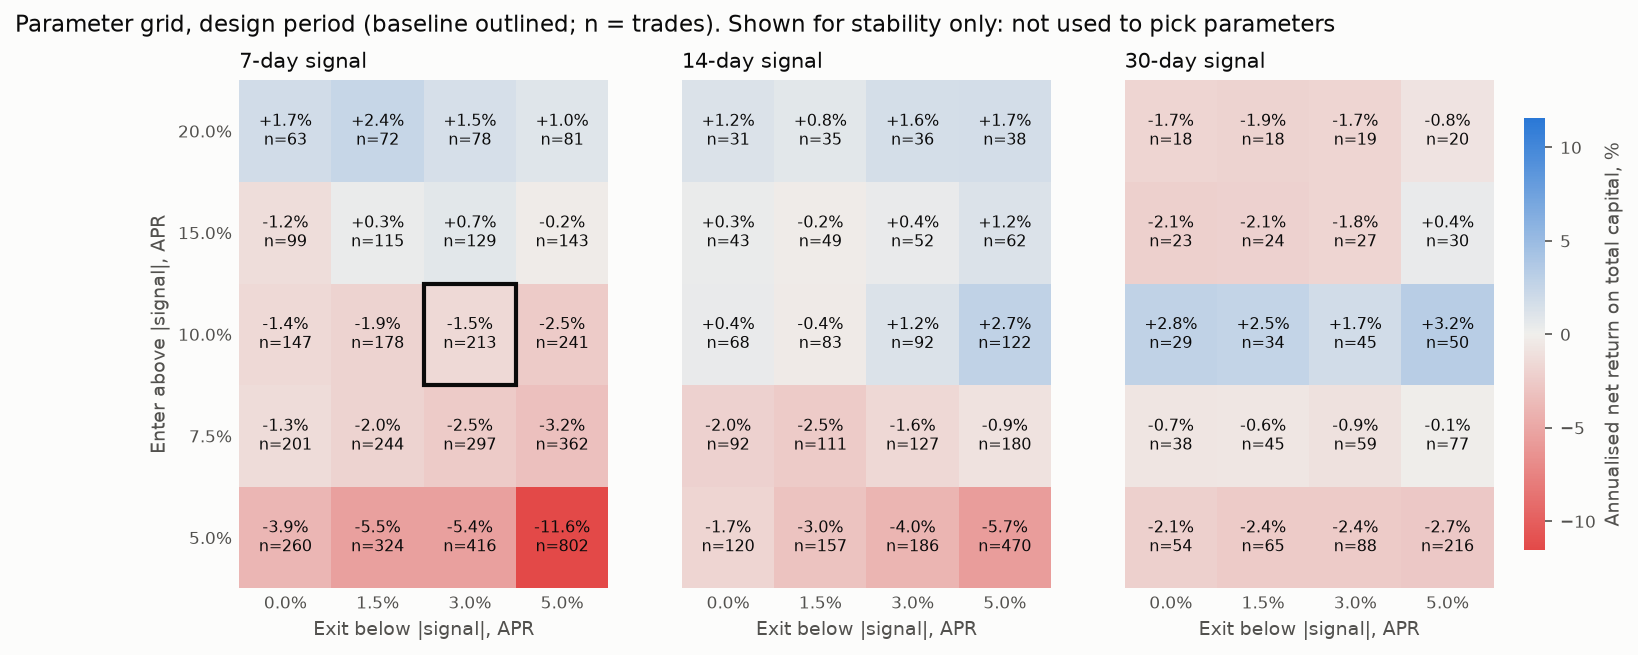

In [5]:
display(Image(filename=str(FIGURES / "robustness_parameter_grid.png")))

In [6]:
pg = res["parameter_grid"]
pg.pivot_table(index=["window_days", "theta_in_apr"], columns="theta_out_apr",
               values="total_pnl").style.format(usd).set_caption("Net P&L, $")

In [7]:
print(f"Positive cells: {(pg['total_pnl'] > 0).sum()} of {len(pg)}")
pg.groupby("window_days")[["total_pnl", "liquidations", "trades"]].agg(["min", "median", "max"]).round(0)

Positive cells: 21 of 60


total_pnl                 liquidations              trades         \
                  min  median     max          min median   max    min median   
window_days                                                                     
7            -33185.0 -4215.0  6995.0         21.0   36.0  52.0   63.0  190.0   
14           -16241.0   146.0  7867.0         14.0   26.0  41.0   31.0   88.0   
30            -7614.0 -3812.0  9192.0         10.0   22.0  32.0   18.0   36.0   

                    
               max  
window_days         
7            802.0  
14           470.0  
30           216.0

## 4. Universe

Each subset keeps $10,000 of total capital per coin (one slot per coin), so returns are
comparable across subsets; with one position per coin and coins not interacting, a subset trades
exactly as it does inside the full run. The majors split is BTC, ETH and SOL
(`robustness.majors`); slippage still treats only BTC and ETH as majors (2 bps), SOL pays 8 bps.

In [8]:
res["universe_split"].style.format(fmt)

,coins,n_coins,total_pnl,capital,ann_return_total_capital,sharpe,max_drawdown_usd,trades,hit_rate,liquidations,rebalances
universe,,,,,,,,,,,
all,"BTC, ETH, SOL, kPEPE, SUI, WIF, TIA, DOGE, WLD, AAVE, APT, kBONK, AVAX, TAO, BNB",15,"-4,270","150,000",-1.49%,-0.61,"-8,881",213,35%,38,313
majors,"BTC, ETH, SOL",3,+92,"30,000",+0.16%,+0.05,"-1,386",27,48%,1,62
rest,"kPEPE, SUI, WIF, TIA, DOGE, WLD, AAVE, APT, kBONK, AVAX, TAO, BNB",12,"-4,363","120,000",-1.90%,-0.72,"-7,615",186,33%,37,251


In [9]:
loo = res["leave_one_out"].sort_values("coin_pnl", ascending=False)
full = M.summary(base)["total_pnl"]
assert (loo["total_pnl"] - (full - loo["coin_pnl"])).abs().max() < 0.01   # coins do not interact
loo.style.format(fmt).set_caption("Leave one coin out (sorted by the dropped coin's own P&L)")

,coin_pnl,total_pnl,capital,ann_return_total_capital,sharpe,max_drawdown_usd,trades,hit_rate,liquidations,rebalances
dropped,,,,,,,,,,
kPEPE,"+3,048","-7,318","140,000",-2.73%,-1.20,"-8,911",196,34%,34,282
AAVE,"+1,603","-5,874","140,000",-2.19%,-0.85,"-9,160",203,32%,37,277
BTC,+503,"-4,774","140,000",-1.78%,-0.68,"-9,057",206,33%,38,310
ETH,+323,"-4,593","140,000",-1.71%,-0.65,"-8,919",205,34%,38,308
BNB,+234,"-4,504","140,000",-1.68%,-0.64,"-8,853",203,34%,38,306
APT,+59,"-4,330","140,000",-1.61%,-0.55,"-9,337",194,36%,36,298
DOGE,-268,"-4,002","140,000",-1.49%,-0.64,"-7,951",204,34%,36,297
WLD,-368,"-3,903","140,000",-1.46%,-0.56,"-8,195",193,36%,33,282
SOL,-734,"-3,537","140,000",-1.32%,-0.58,"-7,400",201,35%,37,259


In [10]:
best = loo.index[0]
print(f"Best coin {best} made {loo.loc[best, 'coin_pnl']:+,.0f}; without it the strategy makes "
      f"{loo.loc[best, 'total_pnl']:+,.0f} ({loo.loc[best, 'ann_return_total_capital']:+.2%}/yr on "
      f"${loo.loc[best, 'capital']:,.0f}).")
print(f"Coins with positive P&L: {(loo['coin_pnl'] > 0).sum()} of {len(loo)}")

Best coin kPEPE made +3,048; without it the strategy makes -7,318 (-2.73%/yr on $140,000).
Coins with positive P&L: 6 of 15


## 5. Time stability

Net P&L per calendar quarter (UTC), split into components; `price_unrealised` is the change in
open positions' unrealised price P&L. The first quarter is August-September 2024 only. Trades are
counted in the quarter they were entered, liquidations in the quarter they happened.

In [11]:
q = res["quarterly"]
q.style.format({c: usd for c in q.columns if c not in ("days", "ann_return_total_capital",
                "trades_entered", "liquidations")} | {"days": "{:.0f}", "trades_entered": "{:.0f}",
                "liquidations": "{:.0f}", "ann_return_total_capital": pct})

,days,hl_funding,bn_funding,price_spread,fees,slippage,transfer_fees,liquidation,price_unrealised,total,ann_return_total_capital,trades_entered,liquidations
quarter,,,,,,,,,,,,,
2024Q3,61,"+1,071",-108,-273,-437,-721,-34,-667,-45,"-1,212",-4.84%,27,5
2024Q4,92,"+6,245","-2,523","+3,619",-446,-656,-93,"-1,519",+49,"+4,676",+12.37%,22,10
2025Q1,90,"+1,112",-68,"-1,027",-529,-844,-51,-143,-4,"-1,555",-4.20%,31,3
2025Q2,91,"+1,552",-254,"-1,590",-623,-946,-49,-780,+15,"-2,675",-7.15%,33,6
2025Q3,92,"+2,934",-910,-7,-596,-931,-31,-332,+48,+176,+0.46%,33,2
2025Q4,92,+190,+563,"-2,570",-497,-816,-11,-564,-59,"-3,763",-9.95%,28,8
2026Q1,90,+163,+437,+114,-415,-674,-12,-240,-16,-644,-1.74%,23,2
2026Q2,91,+357,+395,"+1,161",-323,-543,-32,-299,+11,+726,+1.94%,17,2


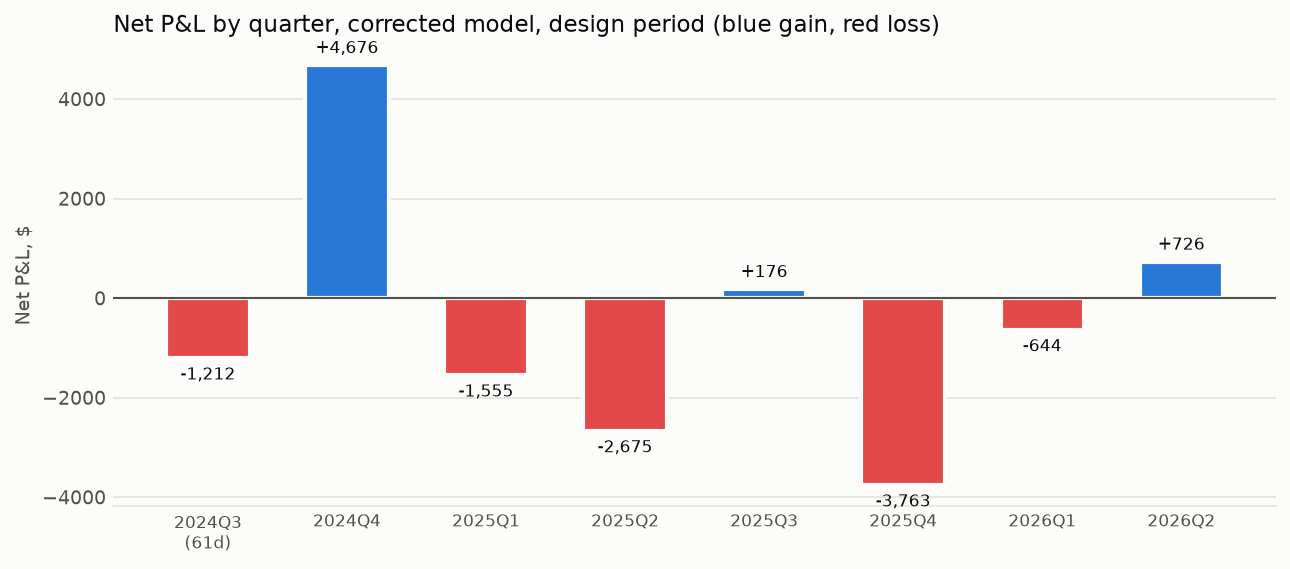

In [12]:
display(Image(filename=str(FIGURES / "robustness_quarterly.png")))

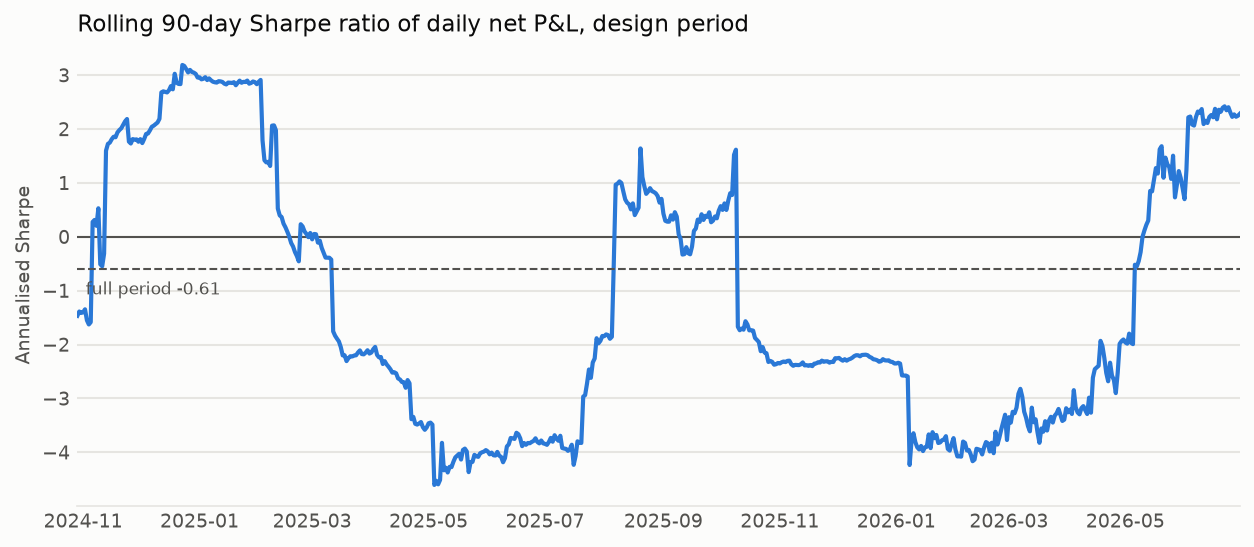

Rolling 90-day Sharpe: min -4.61, median -2.19, max +3.19; above zero on 36% of days


In [13]:
display(Image(filename=str(FIGURES / "robustness_rolling_sharpe.png")))
rs = res["rolling_sharpe"].dropna()
print(f"Rolling 90-day Sharpe: min {rs.min():+.2f}, median {rs.median():+.2f}, max {rs.max():+.2f}; "
      f"above zero on {(rs > 0).mean():.0%} of days")

### Block bootstrap of the Sharpe ratio

Daily net P&L resampled in blocks of 7 consecutive days (moving-block bootstrap; blocks keep
the within-week autocorrelation of P&L), 10,000 resamples, seed 0, percentile interval. It
measures sampling noise in the design period only; it does not capture model or regime risk.

,sharpe,ci_low,ci_high,share_above_zero,days,block_days,resamples
value,-0.605,-1.881,0.841,0.198,699.000,7.000,10000.000


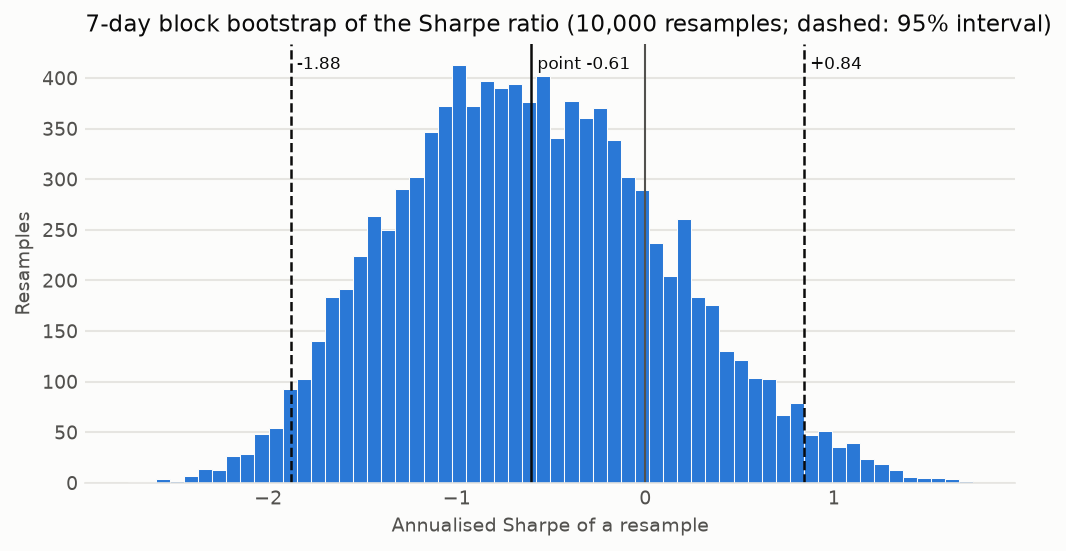

Trades in the design period: 213; gaps behave like roughly 2.3-3.5 independent coins (exploratory analysis), so the effective sample is smaller.


In [14]:
display(res["bootstrap"].to_frame("value").T.style.format("{:.3f}"))
display(Image(filename=str(FIGURES / "robustness_bootstrap_sharpe.png")))
print(f"Trades in the design period: {M.summary(base)['trades']:.0f}; "
      f"gaps behave like roughly 2.3-3.5 independent coins (exploratory analysis), so the effective sample is smaller.")

## 6. Leverage and buffer — sensitivity added after the first backtest run

**Not pre-registered: these settings were added after the first backtest run had been seen.**
Leverage changes each leg's initial margin, so the liquidation distance, the rebalance trigger and
the capital base all change. The buffer is idle cash in this model (never used to top up a leg),
so it changes only the capital base: P&L, liquidations and trades are identical across buffers at
a given leverage, and only the return on total capital moves.

In [15]:
lb = res["leverage_buffer_post_hoc"]
lb.style.format(fmt | {"pnl_liquidated_trades": usd, "pnl_other_trades": usd, "capital_buffer_frac": "{:.0%}".format, "leverage_per_leg": "{:.1f}x".format})\
    .set_caption("Sensitivity added after the first backtest run (not pre-registered)")

,label,leverage_per_leg,capital_buffer_frac,total_pnl,capital,ann_return_total_capital,sharpe,max_drawdown_usd,trades,hit_rate,liquidations,rebalances,pnl_liquidated_trades,pnl_other_trades
0,sensitivity added after the first backtest run,1.5x,0%,"-14,920","200,000",-3.90%,-0.65,"-17,477",212,39%,10,461,"-20,928","+6,008"
1,sensitivity added after the first backtest run,1.5x,25%,"-14,920","250,000",-3.12%,-0.65,"-17,477",212,39%,10,461,"-20,928","+6,008"
2,sensitivity added after the first backtest run,1.5x,50%,"-14,920","300,000",-2.60%,-0.65,"-17,477",212,39%,10,461,"-20,928","+6,008"
3,sensitivity added after the first backtest run,2.0x,0%,"-9,569","150,000",-3.33%,-0.47,"-16,190",213,39%,16,342,"-14,094","+4,525"
4,sensitivity added after the first backtest run,2.0x,25%,"-9,569","187,500",-2.67%,-0.47,"-16,190",213,39%,16,342,"-14,094","+4,525"
5,sensitivity added after the first backtest run,2.0x,50%,"-9,569","225,000",-2.22%,-0.47,"-16,190",213,39%,16,342,"-14,094","+4,525"
6,sensitivity added after the first backtest run,3.0x,0%,"-4,270","100,000",-2.23%,-0.61,"-8,881",213,35%,38,313,"-4,467",+197
7,sensitivity added after the first backtest run,3.0x,25%,"-4,270","125,000",-1.78%,-0.61,"-8,881",213,35%,38,313,"-4,467",+197
8,sensitivity added after the first backtest run,3.0x,50%,"-4,270","150,000",-1.49%,-0.61,"-8,881",213,35%,38,313,"-4,467",+197


### Why lower leverage loses more here (sensitivity added after the first backtest run)

Lower leverage cuts liquidations but moves each leg's liquidation price further away, so a
liquidation that does happen is deeper. On 2025-10-10 Binance mark prices for several alts fell
far below Hyperliquid's (AVAX: Binance mark low $8.50, Hyperliquid 4h close $20.59). The long
Binance leg is closed at its liquidation price and the short Hyperliquid leg only at the next bar
open, after the rebound, so the deeper the liquidation price, the larger the loss (section 7).

## 7. Tail-event sensitivity — sensitivity added after the first backtest run

**Not pre-registered (report/decisions.md, 2026-11-08).** For each leverage (buffer 50%; the buffer does
not change P&L): design-period P&L with and without the daily P&L booked on 2025-10-10 and
2025-10-11 (UTC days, from the daily equity curve), and those two days' share of total P&L. A
share above 100% means the rest of the period made money. Removing the two days' P&L is not a
rerun without them: positions, rebalances and re-arming after those days are as in the full run.
Liquidations are dated by the bar end at which the leg was liquidated.

In [16]:
te = res["tail_event_post_hoc"]
te.style.format({"capital": "{:,.0f}".format, "total_pnl": usd, "pnl_tail_days": usd,
                 "pnl_excl_tail_days": usd, "tail_share_of_total": "{:.0%}".format,
                 "liquidations": "{:.0f}".format, "liquidations_tail_days": "{:.0f}".format,
                 "ann_return_total_capital": pct, "ann_return_excl_tail_days": pct,
                 "sharpe": "{:+.2f}".format, "sharpe_excl_tail_days": "{:+.2f}".format})    .format_index("{:.1f}x".format)    .set_caption("Sensitivity added after the first backtest run (not pre-registered)")

,label,capital,tail_days,total_pnl,pnl_tail_days,pnl_excl_tail_days,tail_share_of_total,liquidations,liquidations_tail_days,ann_return_total_capital,ann_return_excl_tail_days,sharpe,sharpe_excl_tail_days
leverage_per_leg,,,,,,,,,,,,,
1.5x,sensitivity added after the first backtest run,"300,000","2025-10-10, 2025-10-11","-14,920","-16,066","+1,146",108%,10,5,-2.60%,+0.20%,-0.65,+0.20
2.0x,sensitivity added after the first backtest run,"225,000","2025-10-10, 2025-10-11","-9,569","-14,676","+5,106",153%,16,7,-2.22%,+1.19%,-0.47,+1.19
3.0x,sensitivity added after the first backtest run,"150,000","2025-10-10, 2025-10-11","-4,270","-3,376",-894,79%,38,8,-1.49%,-0.31%,-0.61,-0.16


## 8. Failure cases: the five worst trades (corrected baseline)

Ranked by total trade P&L. For each trade: the loss by component, statistics for classifying
the cause, and four panels from 3 days before entry to 3 days after exit:

1. Prices: Hyperliquid bar close (every 4h before 2026-04-09) and its own bar high or low on the
   leg's adverse side (dashed), Binance 1h close, and each leg's
   liquidation reference on its adverse side: the Binance mark low or high for the Binance leg,
   the Binance index (the proxy for Hyperliquid's mark) for the Hyperliquid leg. Dots: exit prices.
2. The price spread between the two venues' closes.
3. Realised funding on each venue (hourly-equivalent, % APR) and the strategy signal.
4. The trade's running P&L: funding as booked by the engine (reconstructed; checked against the
   ledger below) and both legs marked at bar closes before costs; the dot is the final total.

Worst leg moves are measured during the hold against the leg's entry price, on its liquidation
reference (index for the Hyperliquid leg, mark for the Binance leg); a negative number is a move
against the leg. Times are UTC and stamp the end of each hour. The cause is left to the reader.

In [17]:
from src.analysis import failure_cases as FC
fc = FC.run(cfg, inputs, base.trades)
tbl = fc["table"]
assert tbl[["hl_funding_recon_error", "bn_funding_recon_error"]].abs().max().max() < 1e-6
tbl[E.COMPONENTS + ["total"]].style.format(usd).set_caption("Loss by component, $")

,hl_funding,bn_funding,price_spread,fees,slippage,transfer_fees,liquidation,total
rank,,,,,,,,
1,+117,-31,"-1,640",-13,-23,+0,-68,"-1,657"
2,+14,+24,"-1,180",-13,-22,+0,-67,"-1,244"
3,+1,-8,-888,-13,-22,+0,-67,-997
4,+5,+26,-764,-15,-25,+0,-121,-894
5,+175,-43,-872,-13,-22,-2,-63,-840


In [18]:
cols = ["coin", "position", "entry", "exit", "hold_days", "exit_reason", "liquidated_leg",
        "rebalances", "signal_at_entry_apr", "signal_at_exit_apr", "entry_spread_bps",
        "exit_spread_bps", "hl_leg_worst_index_move", "hl_leg_worst_own_trade_move",
        "bn_leg_worst_mark_move",
        "mean_f_hl_apr", "mean_f_bn_apr"]
tbl[cols].T

rank,1,2,3,4,5
coin,TAO,SOL,DOGE,TIA,AVAX
position,short HL / long BN,short HL / long BN,short HL / long BN,short HL / long BN,short HL / long BN
entry,2025-09-16 20:00:00,2025-09-20 04:00:00,2025-10-08 16:00:00,2025-05-05 12:00:00,2025-09-10 16:00:00
exit,2025-10-11 00:00:00,2025-10-11 00:00:00,2025-10-11 00:00:00,2025-05-08 08:00:00,2025-10-11 00:00:00
hold_days,24.166667,20.833333,2.333333,2.833333,30.333333
exit_reason,liquidation,liquidation,liquidation,liquidation,liquidation
liquidated_leg,binance,binance,binance,hyperliquid,binance
rebalances,0,0,0,0,2
signal_at_entry_apr,0.10303,0.104393,0.101729,0.102156,0.102866
signal_at_exit_apr,0.13386,-0.064409,0.058975,0.130836,0.074443


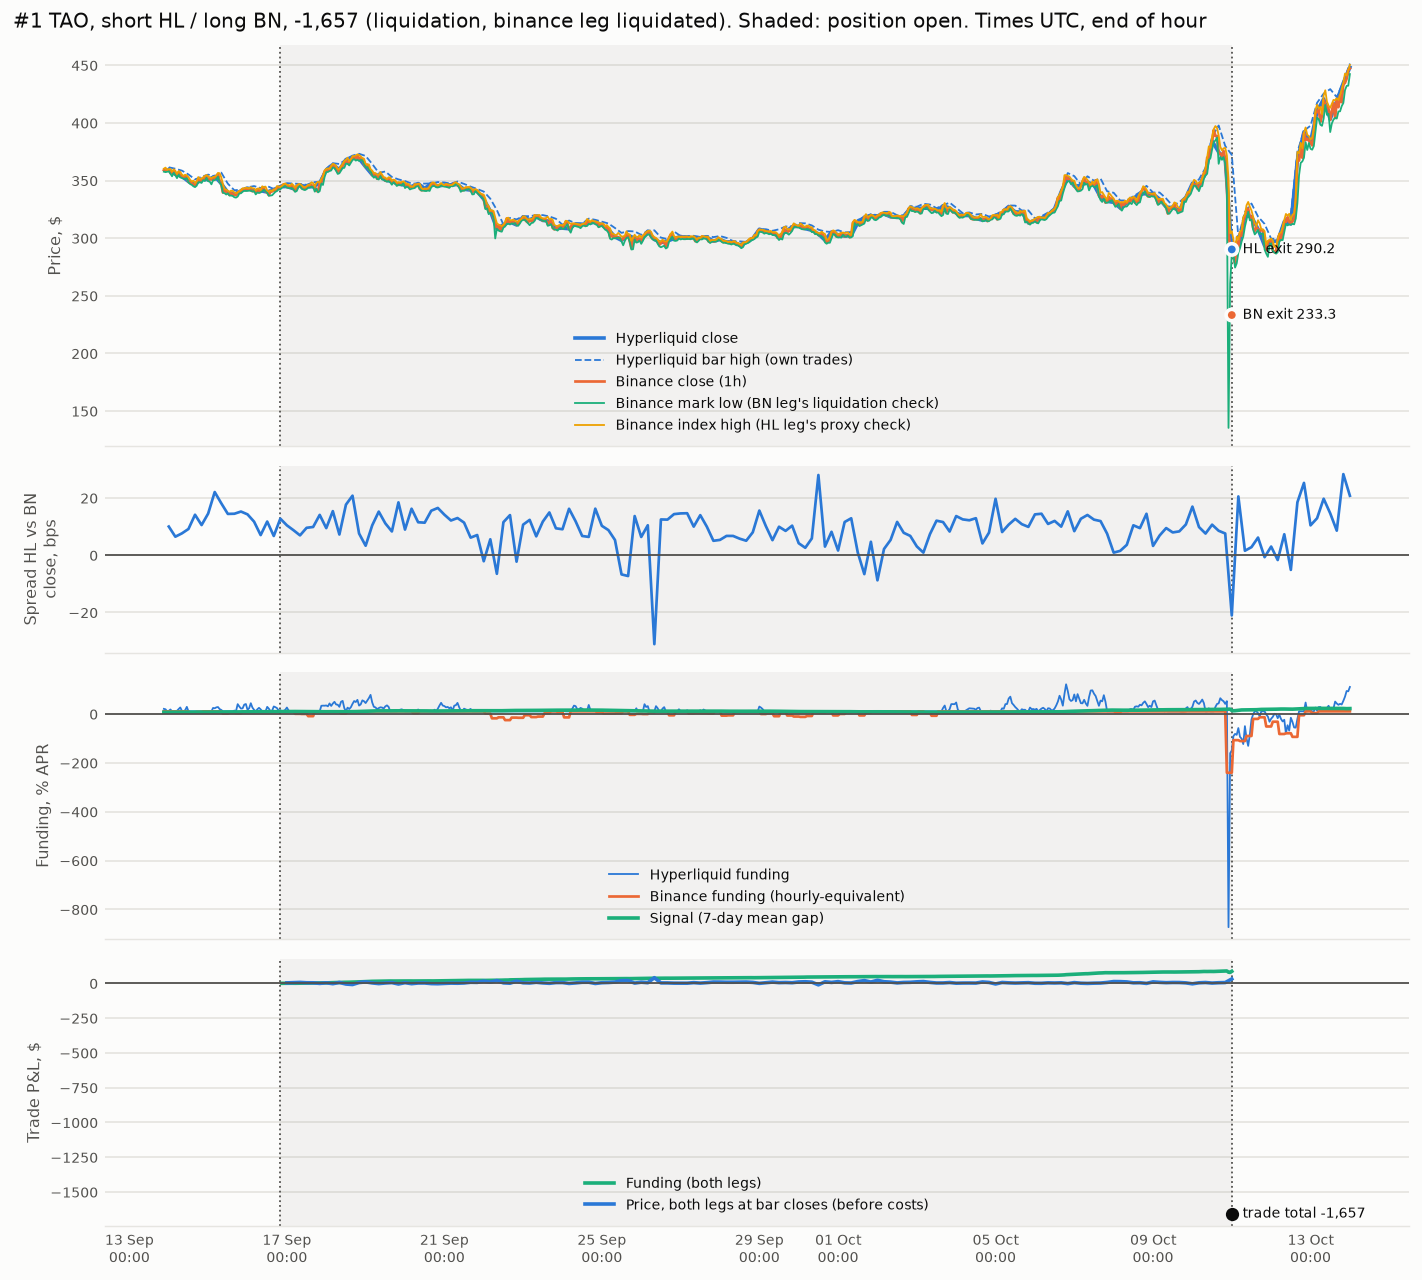

In [19]:
display(Image(filename=str(FIGURES / f"failure_case_{1}_{tbl.loc[1, 'coin']}.png")))

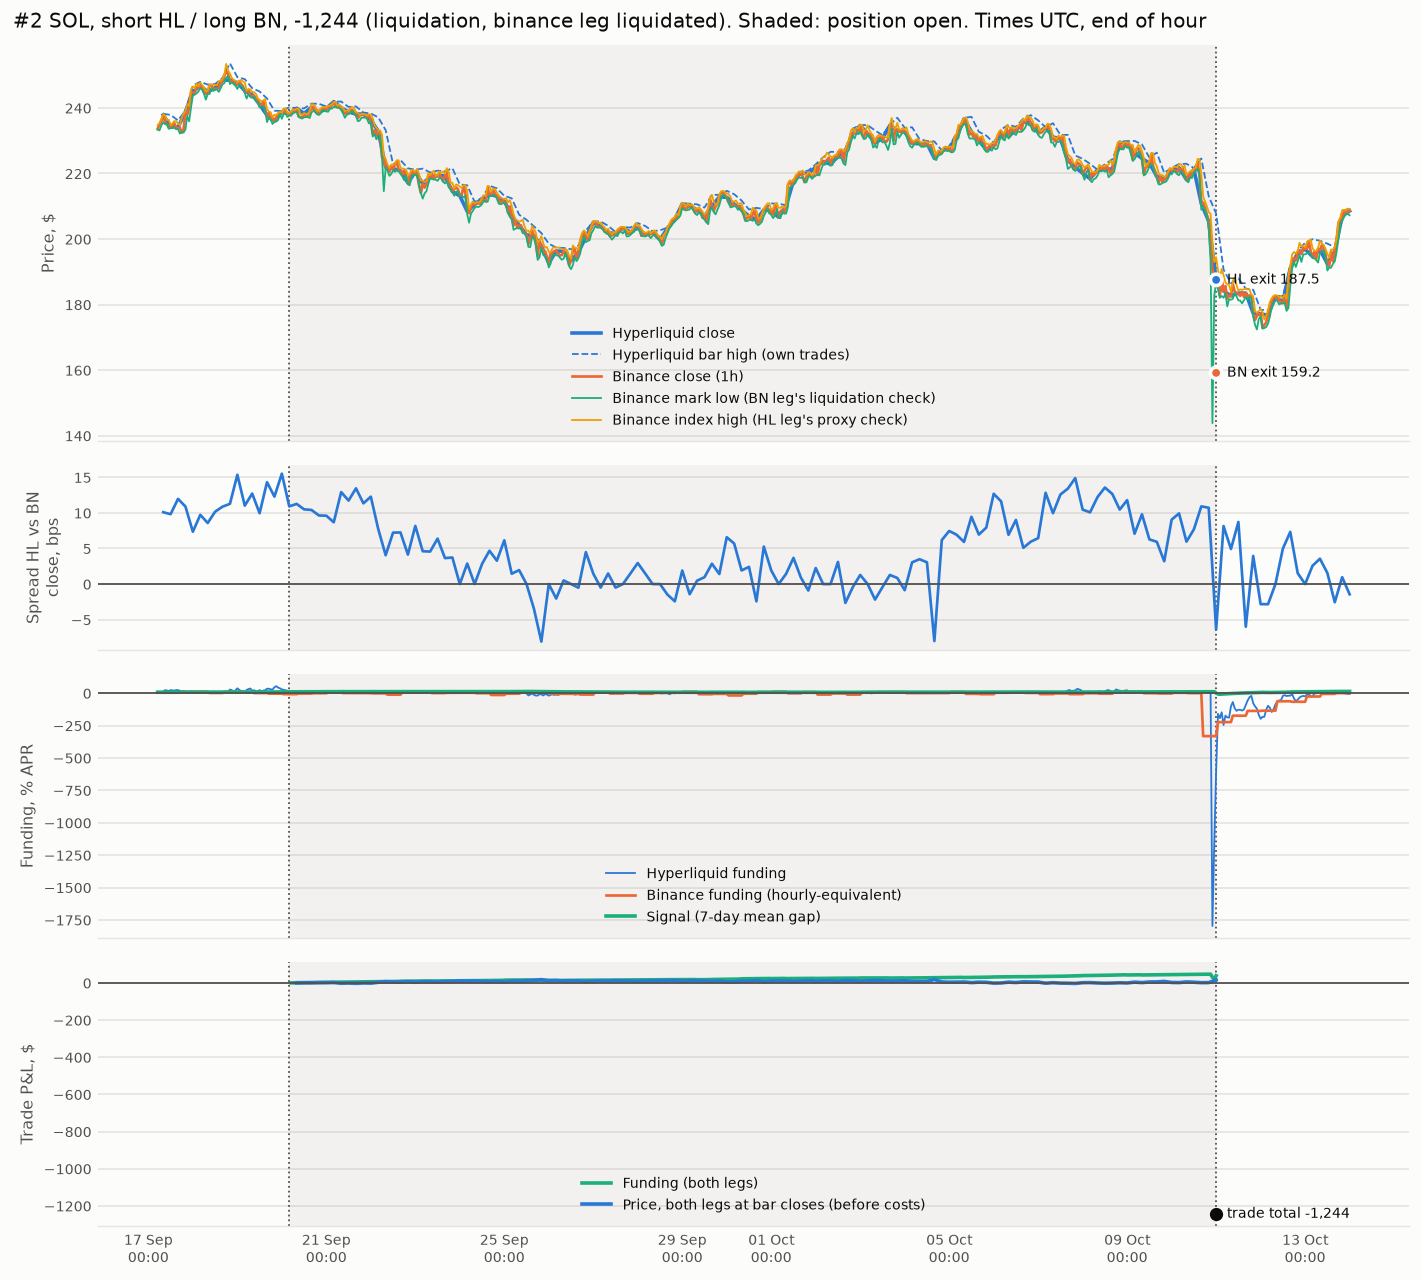

In [20]:
display(Image(filename=str(FIGURES / f"failure_case_{2}_{tbl.loc[2, 'coin']}.png")))

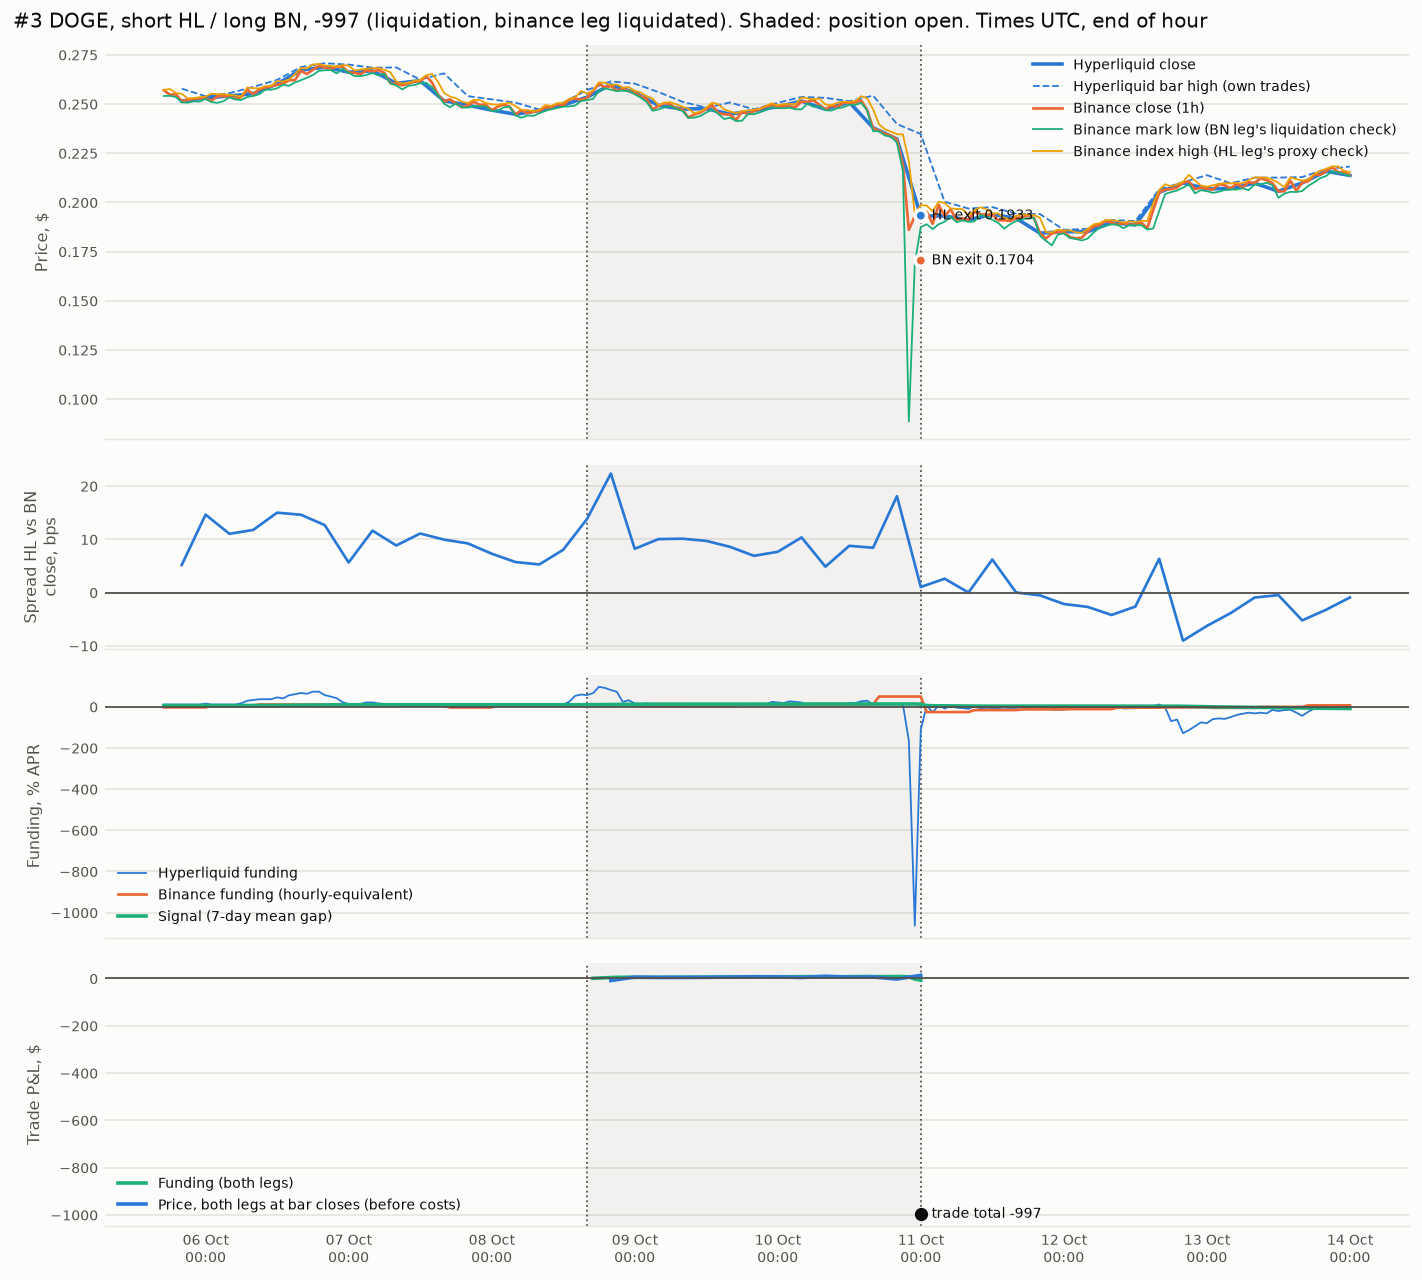

In [21]:
display(Image(filename=str(FIGURES / f"failure_case_{3}_{tbl.loc[3, 'coin']}.png")))

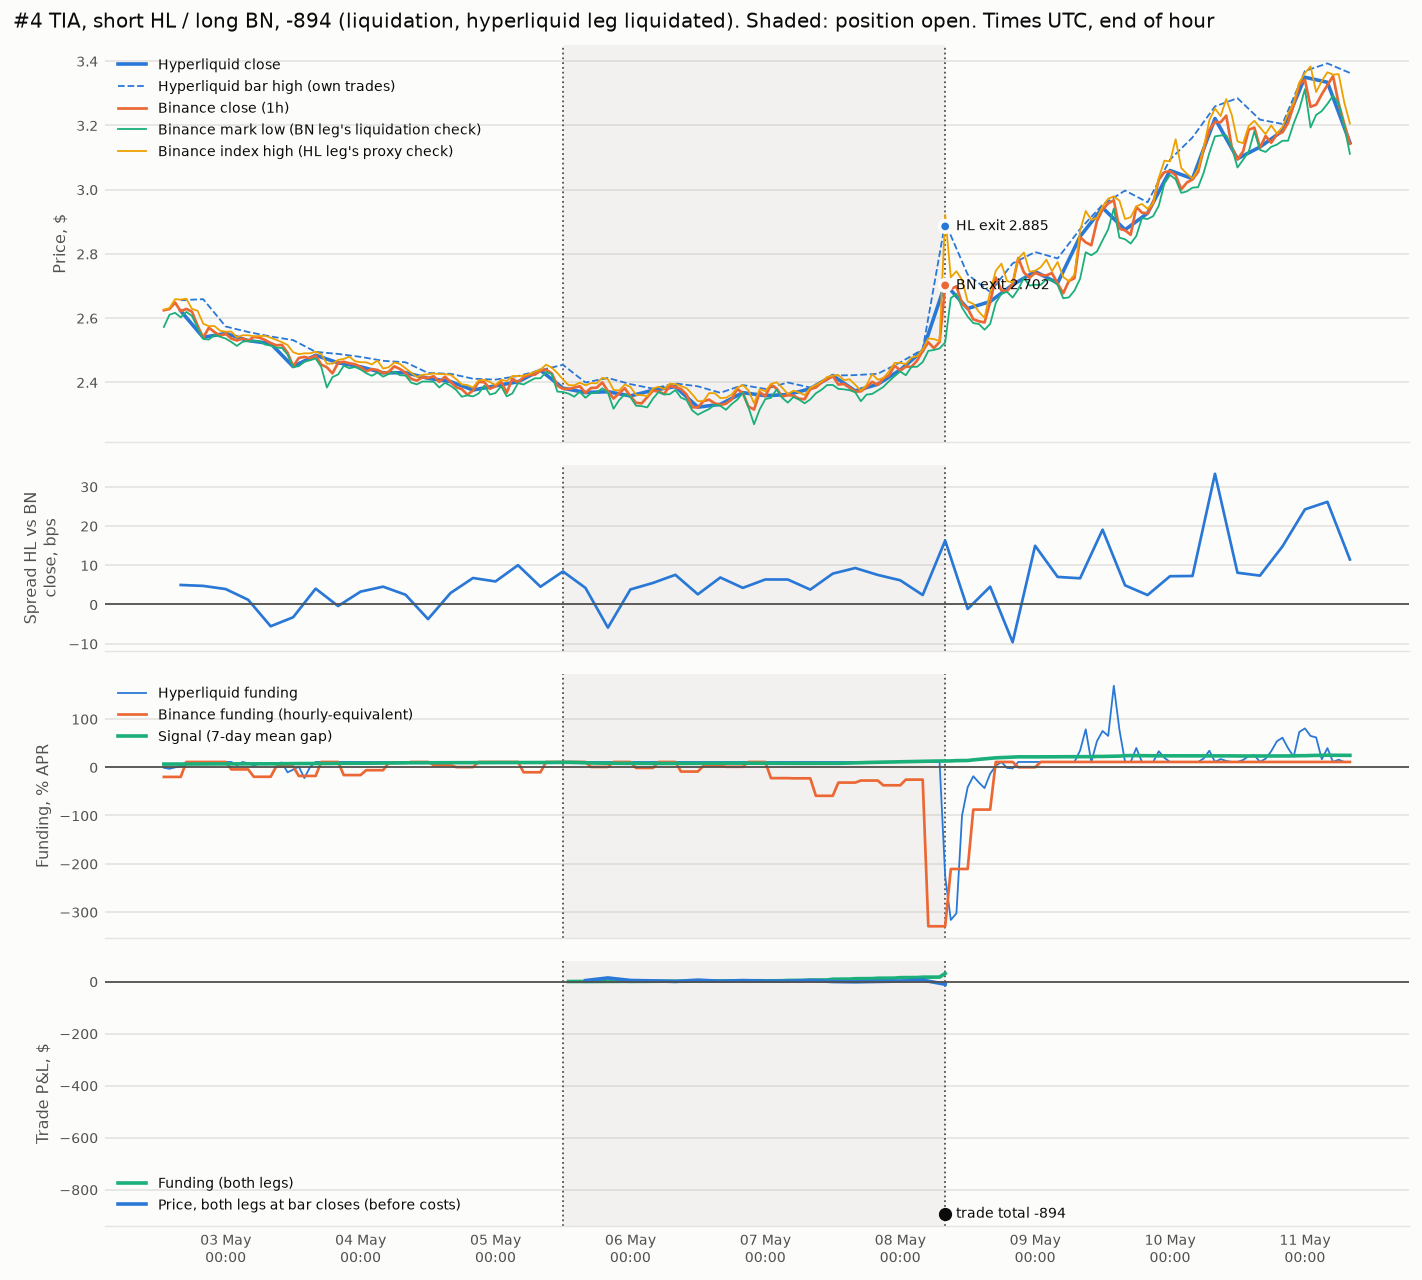

In [22]:
display(Image(filename=str(FIGURES / f"failure_case_{4}_{tbl.loc[4, 'coin']}.png")))

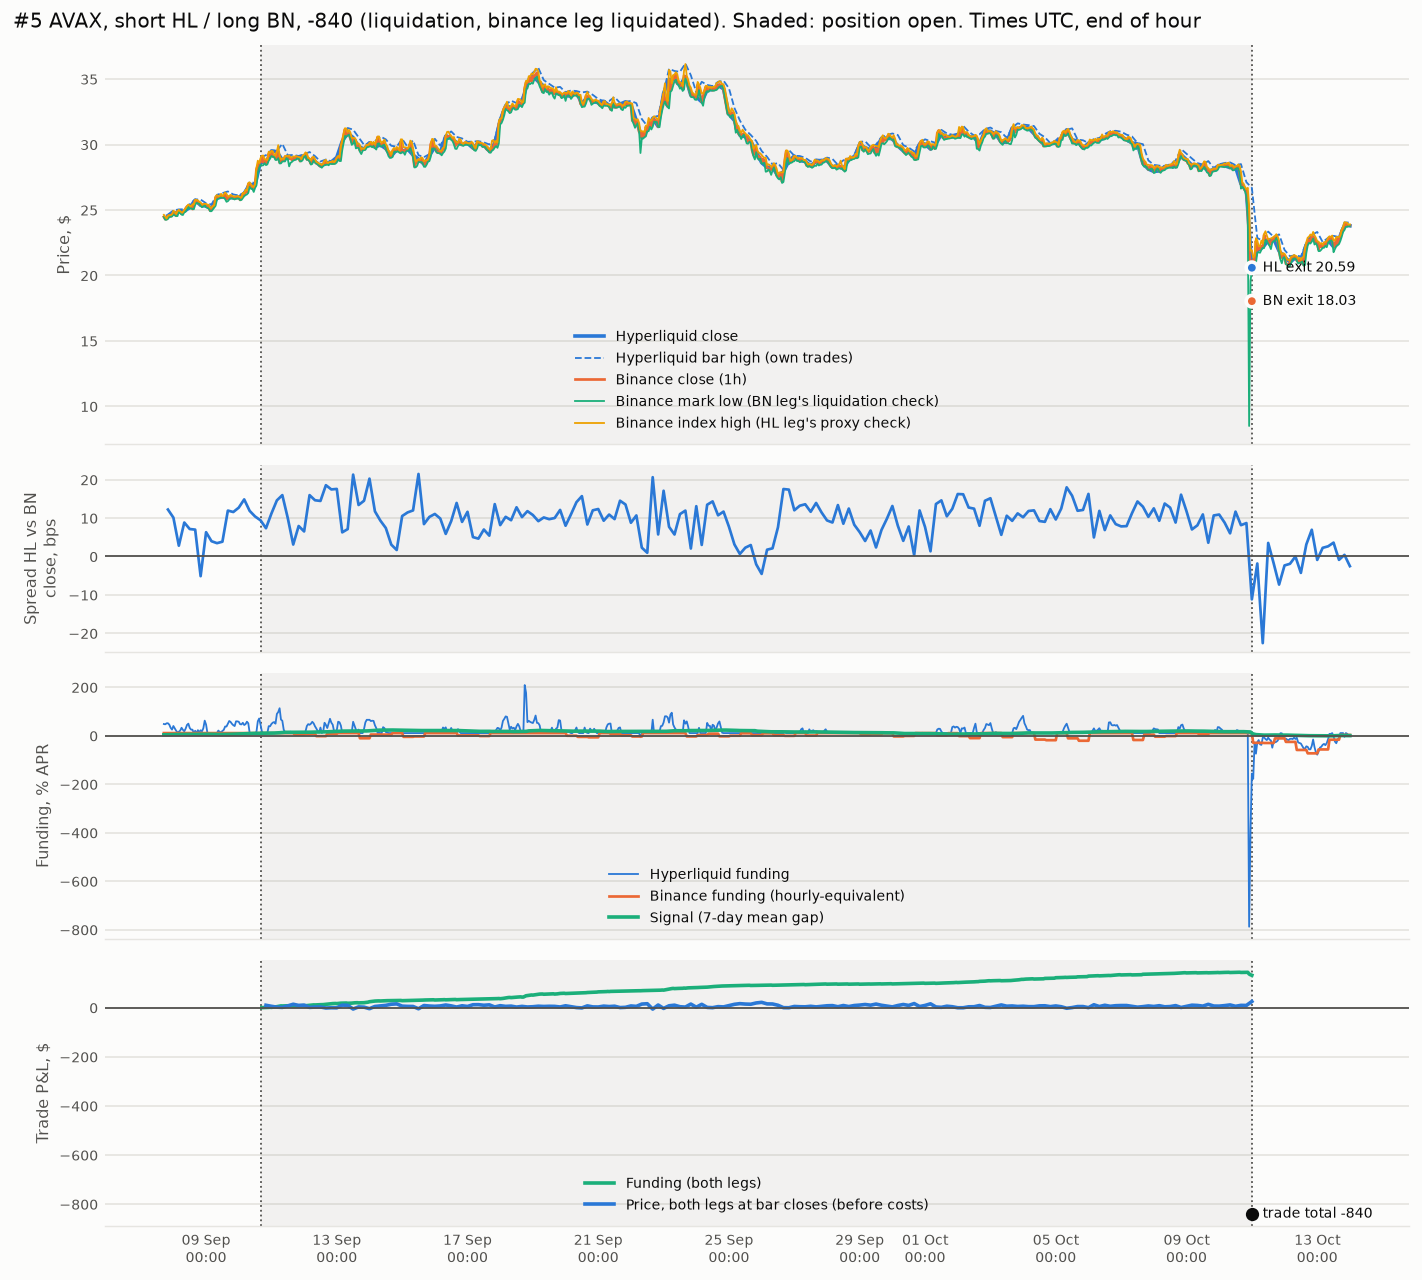

In [23]:
display(Image(filename=str(FIGURES / f"failure_case_{5}_{tbl.loc[5, 'coin']}.png")))